<a href="https://colab.research.google.com/github/syedh99/SMS_Spam_Proj/blob/main/SMS_Spam_Checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluating Prompting Strategies for SMS Spam Detection

**CSI-4130/5130 — Artificial Intelligence Course Project**

## Project Overview

This project evaluates how well an instruction-tuned
Large Language Model (LLM) can classify SMS messages
as spam or legitimate (ham).

We compare three approaches:

1. TF-IDF + Logistic Regression (traditional ML baseline)
2. FLAN-T5 with zero-shot prompting
3. FLAN-T5 with few-shot prompting

We also investigate whether disguising certain words
(e.g., "free" → "fr33") affects classification accuracy.

## Research Questions

- How does zero-shot prompting compare with traditional ML?
- Does few-shot prompting improve classification performance?
- How robust are these approaches to disguised spam keywords?

## Technology

- Python and Google Colab
- PyTorch and Hugging Face Transformers
- Scikit-learn
- Google FLAN-T5-base
- UCI SMS Spam Collection

The project uses a pretrained LLM without fine-tuning.

## 1. Environment Setup

The project is designed to run on Google Colab
with an NVIDIA Tesla T4 GPU.

Required libraries:
- PyTorch
- Transformers
- SentencePiece
- Scikit-learn
- Pandas
- NumPy
- Matplotlib

In [1]:
%pip -q install "sentencepiece>=0.2.0" "scikit-learn>=1.6"

In [2]:
import io
import random
import re
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

# Configuration
SEED = 42

# Number of SMS messages used for evaluation
EVAL_SAMPLES = 240

# Language model
MODEL_NAME = "google/flan-t5-base"

# Inference configuration
BATCH_SIZE = 12
MAX_INPUT_TOKENS = 384
MAX_OUTPUT_TOKENS = 8

# Output directory
OUTPUT_DIR = Path("project_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# GPU / CPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Model:", MODEL_NAME)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Evaluation messages:", EVAL_SAMPLES)

PyTorch version: 2.11.0+cpu
Model: google/flan-t5-base
Device: cpu
Evaluation messages: 240


## 2. Dataset

We use the publicly available UCI SMS Spam Collection.

The dataset contains SMS messages labeled:

- ham: Legitimate messages
- spam: Unsolicited or unwanted messages

Source:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

Exact duplicate messages are removed before splitting
to prevent them from appearing in both training and
testing datasets.

In [3]:
DATA_URLS = [
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
]

def fetch_sms_collection():

    last_error = None

    for url in DATA_URLS:

        try:
            print("Downloading dataset:", url)

            with urllib.request.urlopen(url, timeout=35) as response:
                raw_zip = response.read()

            with zipfile.ZipFile(io.BytesIO(raw_zip)) as archive:

                members = [
                    n for n in archive.namelist()
                    if n.split("/")[-1] == "SMSSpamCollection"
                ]

                if not members:
                    raise ValueError("Dataset file not found")

                contents = archive.read(
                    members[0]
                ).decode("latin-1")

            rows = []

            for line in contents.splitlines():

                label, separator, message = line.partition("\t")

                if (
                    separator
                    and label in {"ham", "spam"}
                    and message.strip()
                ):
                    rows.append((label, message.strip()))

            if len(rows) < 5000:
                raise ValueError("Unexpected dataset size")

            return pd.DataFrame(
                rows,
                columns=["label", "text"]
            )

        except Exception as exc:
            last_error = exc
            print("Download failed:", exc)

    raise RuntimeError(
        "Could not download the dataset"
    ) from last_error


# Load dataset
df_raw = fetch_sms_collection()

# Remove duplicate messages
df = df_raw.drop_duplicates(
    subset=["text"]
).reset_index(drop=True)

print("Original records:", len(df_raw))
print("Unique records:", len(df))

# Class distribution
display(df["label"].value_counts())

# First five messages
display(df.head())

Original records: 5574
Unique records: 5160


,count
label,
ham,4518
spam,642


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Train/Test Split

We divide the dataset into:

- 75% training data
- 25% testing data

We use stratified splitting to preserve approximately
the same ratio of spam and ham messages.

All three methods are evaluated on the same held-out
sample of messages.

The LLM's few-shot examples come only from training data.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.25,
    random_state=SEED,
    stratify=df["label"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify no exact-text overlap
assert set(train_df.text).isdisjoint(set(test_df.text))

assert 0 < EVAL_SAMPLES <= len(test_df)

# Select a fixed evaluation sample
if EVAL_SAMPLES < len(test_df):

    eval_df, _ = train_test_split(
        test_df,
        train_size=EVAL_SAMPLES,
        random_state=SEED,
        stratify=test_df["label"]
    )

else:
    eval_df = test_df.copy()

eval_df = eval_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Evaluation samples:", len(eval_df))

print("\nEvaluation class distribution:")
display(eval_df["label"].value_counts())

Training samples: 3870
Testing samples: 1290
Evaluation samples: 240

Evaluation class distribution:


,count
label,
ham,210
spam,30


## 4. Traditional Machine Learning Baseline

We train a Logistic Regression classifier using
TF-IDF text features.

TF-IDF represents messages numerically based on
word frequency and importance.

Logistic Regression predicts whether a message
belongs to the ham or spam class.

This provides a baseline for evaluating the
language model's performance.

In [5]:
baseline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),

    (
        "logreg",
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=SEED
        )
    )

])

# Train classifier
baseline.fit(
    train_df["text"],
    train_df["label"]
)

print("Baseline classifier trained successfully!")

# Simple test
sample_message = "Congratulations! You won a free prize!"

prediction = baseline.predict([sample_message])[0]

print("Message:", sample_message)
print("Prediction:", prediction)

Baseline classifier trained successfully!
Message: Congratulations! You won a free prize!
Prediction: spam


## 5. Spam Keyword Obfuscation

Spam messages often contain recognizable keywords,
such as "free", "win", or "prize".

We investigate the effects of replacing some letters
with visually similar characters.

Examples:

- free → fr33
- win → w1n
- claim → cl@im
- prize → pr1ze

We evaluate every method using both the original
and modified messages.

Some messages will remain unchanged if they do not
contain any keywords from our predefined dictionary.

In [6]:
OBFUSCATIONS = {
    "free": "fr33",
    "win": "w1n",
    "winner": "w1nn3r",
    "prize": "pr1ze",
    "urgent": "urg3nt",
    "claim": "cl@im",
    "cash": "ca$h",
    "call": "c@ll",
    "reply": "r3ply",
    "offer": "0ffer",
    "bonus": "b0nus",
    "credit": "cr3dit"
}

# Create regular expression
_PATTERN = re.compile(
    r"\b(?:" +
    "|".join(
        map(
            re.escape,
            sorted(
                OBFUSCATIONS,
                key=len,
                reverse=True
            )
        )
    ) +
    r")\b",
    re.IGNORECASE
)

def obfuscate(text):

    return _PATTERN.sub(
        lambda match: OBFUSCATIONS[
            match.group(0).lower()
        ],
        text
    )


# Generate modified SMS messages
eval_df["obfuscated_text"] = (
    eval_df["text"].map(obfuscate)
)

# Identify changed messages
eval_df["was_changed"] = (
    eval_df["text"] != eval_df["obfuscated_text"]
)

print(
    "Messages modified:",
    eval_df["was_changed"].sum()
)

print(
    "Total evaluation messages:",
    len(eval_df)
)

print("\nModified messages by class:")
display(
    eval_df.groupby("label")["was_changed"].sum()
)

# Display some examples
display(
    eval_df.loc[
        eval_df["was_changed"],
        ["label", "text", "obfuscated_text"]
    ].head()
)

Messages modified: 48
Total evaluation messages: 240

Modified messages by class:


,was_changed
label,
ham,23
spam,25


,label,text,obfuscated_text
13,ham,This is wishing you a great day. Moji told me ...,This is wishing you a great day. Moji told me ...
18,spam,74355 XMAS iscoming & ur awarded either Â£500 ...,74355 XMAS iscoming & ur awarded either Â£500 ...
20,spam,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...
21,spam,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...
28,ham,"Sorry, in meeting I'll call you later","Sorry, in meeting I'll c@ll you later"


## 6. Load the Language Model

We use Google's FLAN-T5-base, an instruction-tuned
encoder-decoder language model.

FLAN-T5 can follow natural language instructions
without requiring task-specific fine-tuning.

We will evaluate two prompting methods:

1. Zero-shot: No labeled examples provided
2. Few-shot: Four labeled examples provided

Both methods use the same model checkpoint.

In [7]:
print("Loading language model:", MODEL_NAME)

start_load = time.perf_counter()

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# Load pretrained model
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    use_safetensors=True
)

# Move model to GPU
model = model.to(DEVICE)

# Evaluation mode
model.eval()

elapsed = time.perf_counter() - start_load

print("Model loaded successfully!")
print("Device:", DEVICE)
print(f"Load time: {elapsed:.2f} seconds")

Loading language model: google/flan-t5-base


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model loaded successfully!
Device: cpu
Load time: 37.11 seconds


## 7. Prompting Strategies

### Zero-Shot Prompting

The model is instructed to classify a message
without seeing any labeled examples.

### Few-Shot Prompting

The model is given four labeled examples:

- Two legitimate messages
- Two spam messages

The examples are selected from the training dataset.

Both approaches use the same classification
instructions and generation settings.

In [10]:
# Improved prompt engineering experiment

INSTRUCTIONS = (
    "You are classifying SMS text messages.\n"
    "Spam: Unwanted advertisements, scams, fake prizes, "
    "and unsolicited promotional messages.\n"
    "Ham: Normal personal messages, conversations, "
    "appointments, and routine communication.\n"
    "Respond with only one word: ham or spam."
)

# Hand-written examples, not from the test dataset
EXAMPLES = [
    ("Are we still meeting for dinner tonight?", "ham"),
    ("Hey, I'll call you when I get home.", "ham"),
    ("WIN a FREE CASH PRIZE! Claim it now!", "spam"),
    ("Congratulations! Click here to collect your reward.", "spam")
]


def build_prompt(message, strategy):

    prompt = INSTRUCTIONS + "\n\n"

    if strategy == "Few-shot":

        for text, label in EXAMPLES:
            prompt += (
                f"SMS: {text}\n"
                f"Label: {label}\n\n"
            )

    prompt += (
        f"SMS: {message}\n"
        "Label:"
    )

    return prompt


def parse_label(generation):

    cleaned = re.sub(
        r"[^a-z]",
        "",
        generation.lower().strip()
    )

    if cleaned in {"spam", "ham"}:
        return cleaned

    return "invalid"


@torch.inference_mode()
def flan_predict(messages, strategy):

    messages = list(messages)

    raw_outputs = []

    started = time.perf_counter()

    # Process messages in batches
    for offset in range(0, len(messages), BATCH_SIZE):

        batch = messages[
            offset:offset + BATCH_SIZE
        ]

        # Build prompts
        prompts = [
            build_prompt(str(m), strategy)
            for m in batch
        ]

        # Tokenize
        encoded = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS
        ).to(DEVICE)

        # Generate predictions
        generated = model.generate(
            **encoded,
            max_new_tokens=MAX_OUTPUT_TOKENS,
            do_sample=False
        )

        # Decode predictions
        decoded = tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )

        raw_outputs.extend(decoded)

        # Progress updates
        if (
            offset == 0
            or (offset // BATCH_SIZE + 1) % 5 == 0
        ):

            completed = min(
                offset + BATCH_SIZE,
                len(messages)
            )

            print(
                f"{strategy}: {completed}/{len(messages)}"
            )

    seconds = time.perf_counter() - started

    predictions = [
        parse_label(raw)
        for raw in raw_outputs
    ]

    return predictions, raw_outputs, seconds


# Quick sanity test before running the full experiment
test_messages = [
    "Hey, are you coming over tonight?",
    "WIN a FREE prize! Claim your cash now!",
    "Your appointment is confirmed for Monday."
]

for strategy in ["Zero-shot", "Few-shot"]:

    predicted, raw, seconds = flan_predict(
        test_messages,
        strategy
    )

    print(f"\n{strategy} Results:")

    for message, label in zip(test_messages, predicted):
        print(f"{label.upper():5} | {message}")

Zero-shot: 3/3

Zero-shot Results:
HAM   | Hey, are you coming over tonight?
SPAM  | WIN a FREE prize! Claim your cash now!
HAM   | Your appointment is confirmed for Monday.
Few-shot: 3/3

Few-shot Results:
HAM   | Hey, are you coming over tonight?
SPAM  | WIN a FREE prize! Claim your cash now!
HAM   | Your appointment is confirmed for Monday.


## 8. Generate Predictions

We evaluate three methods:

1. TF-IDF + Logistic Regression
2. FLAN-T5 Zero-Shot
3. FLAN-T5 Few-Shot

Each method is evaluated on:

- Original SMS messages
- Obfuscated SMS messages

The language model uses greedy decoding
to reduce output randomness.

Outputs other than "spam" or "ham" are
classified as invalid.

In [11]:
def parse_label(generation):

    cleaned = re.sub(
        r"[^a-z]",
        "",
        generation.lower().strip()
    )

    if cleaned in {"spam", "ham"}:
        return cleaned

    return "invalid"


@torch.inference_mode()
def flan_predict(messages, strategy):

    messages = list(messages)

    raw_outputs = []

    started = time.perf_counter()

    # Process messages in batches
    for offset in range(0, len(messages), BATCH_SIZE):

        batch = messages[
            offset:offset + BATCH_SIZE
        ]

        # Build prompts
        prompts = [
            build_prompt(str(m), strategy)
            for m in batch
        ]

        # Tokenize
        encoded = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS
        ).to(DEVICE)

        # Generate predictions
        generated = model.generate(
            **encoded,
            max_new_tokens=MAX_OUTPUT_TOKENS,
            do_sample=False
        )

        # Decode predictions
        decoded = tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )

        raw_outputs.extend(decoded)

        # Progress updates
        if (
            offset == 0
            or (offset // BATCH_SIZE + 1) % 5 == 0
        ):

            completed = min(
                offset + BATCH_SIZE,
                len(messages)
            )

            print(
                f"{strategy}: {completed}/{len(messages)}"
            )

    seconds = time.perf_counter() - started

    predictions = [
        parse_label(raw)
        for raw in raw_outputs
    ]

    return predictions, raw_outputs, seconds


# Ground-truth labels
y_true = eval_df["label"].tolist()

# Store predictions and runtimes
predictions = {}
runtimes = {}

# Original and obfuscated experiments
for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:

    messages = eval_df[column].tolist()

    # Traditional ML baseline
    baseline_name = ("TF-IDF + LR", scenario)

    started = time.perf_counter()

    predictions[baseline_name] = (
        baseline.predict(messages).tolist()
    )

    runtimes[baseline_name] = (
        time.perf_counter() - started
    )

    # LLM prompting strategies
    for method in ["Zero-shot", "Few-shot"]:

        print(f"\nRunning {method} on {scenario} SMS")

        key = (method, scenario)

        parsed, raw, seconds = flan_predict(
            messages,
            method
        )

        predictions[key] = parsed
        runtimes[key] = seconds

        # Save raw model outputs
        column_name = (
            f"raw_{method.replace('-', '_')}_"
            f"{scenario.lower()}"
        )

        eval_df[column_name] = raw


print("\nAll experiments completed successfully!")


Running Zero-shot on Original SMS
Zero-shot: 12/240
Zero-shot: 60/240
Zero-shot: 120/240
Zero-shot: 180/240
Zero-shot: 240/240

Running Few-shot on Original SMS
Few-shot: 12/240
Few-shot: 60/240
Few-shot: 120/240
Few-shot: 180/240
Few-shot: 240/240

Running Zero-shot on Obfuscated SMS
Zero-shot: 12/240
Zero-shot: 60/240
Zero-shot: 120/240
Zero-shot: 180/240
Zero-shot: 240/240

Running Few-shot on Obfuscated SMS
Few-shot: 12/240
Few-shot: 60/240
Few-shot: 120/240
Few-shot: 180/240
Few-shot: 240/240

All experiments completed successfully!


## 9. Model Evaluation

We evaluate classification performance using:

- Accuracy
- Precision
- Recall
- F1-score
- Inference time

Accuracy:
The proportion of messages classified correctly.

Precision:
Of messages predicted as spam, how many were spam?

Recall:
Of actual spam messages, how many were detected?

F1-score:
The harmonic mean of precision and recall.

Because legitimate messages are more common than
spam messages, F1-score and recall are particularly
important for evaluating spam detection.

In [12]:
def calculate_metrics(
    truth,
    pred,
    method,
    scenario,
    n_changed,
    seconds
):

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            truth,
            pred,
            labels=["spam"],
            zero_division=0
        )
    )

    return {
        "method": method,
        "scenario": scenario,
        "n": len(truth),
        "changed_messages_in_full_set": n_changed,
        "accuracy": accuracy_score(truth, pred),
        "spam_precision": float(precision[0]),
        "spam_recall": float(recall[0]),
        "spam_f1": float(f1[0]),
        "invalid_outputs": sum(
            p == "invalid" for p in pred
        ),
        "inference_seconds": round(seconds, 2)
    }


# Calculate metrics for all experiments
results = pd.DataFrame([

    calculate_metrics(
        y_true,
        pred,
        method,
        scenario,
        int(eval_df["was_changed"].sum()),
        runtimes[(method, scenario)]
    )

    for (method, scenario), pred in predictions.items()

]).sort_values(
    ["method", "scenario"]
).reset_index(drop=True)


print("FULL EVALUATION RESULTS")

display(results.round(3))

# Save results
results.to_csv(
    OUTPUT_DIR / "metrics.csv",
    index=False
)


# Evaluate only messages actually changed
changed_idx = np.flatnonzero(
    eval_df["was_changed"].to_numpy()
)

changed_rows = []

if len(changed_idx):

    changed_truth = [
        y_true[i] for i in changed_idx
    ]

    for (method, scenario), pred in predictions.items():

        changed_pred = [
            pred[i] for i in changed_idx
        ]

        changed_rows.append(
            calculate_metrics(
                changed_truth,
                changed_pred,
                method,
                scenario,
                len(changed_idx),
                runtimes[(method, scenario)]
            )
        )


changed_results = pd.DataFrame(changed_rows)

print("\nRESULTS ON MODIFIED MESSAGES ONLY")

if not changed_results.empty:

    display(
        changed_results[
            [
                "method",
                "scenario",
                "n",
                "spam_precision",
                "spam_recall",
                "spam_f1",
                "accuracy"
            ]
        ].round(3)
    )

changed_results.to_csv(
    OUTPUT_DIR / "metrics_changed_only.csv",
    index=False
)

FULL EVALUATION RESULTS


,method,scenario,n,changed_messages_in_full_set,accuracy,spam_precision,spam_recall,spam_f1,invalid_outputs,inference_seconds
0,Few-shot,Obfuscated,240,48,0.462,0.189,1.000,0.317,0,194.17
1,Few-shot,Original,240,48,0.467,0.190,1.000,0.319,0,192.02
2,TF-IDF + LR,Obfuscated,240,48,0.975,0.929,0.867,0.897,0,0.02
3,TF-IDF + LR,Original,240,48,0.979,0.931,0.900,0.915,0,0.02
4,Zero-shot,Obfuscated,240,48,0.808,0.340,0.567,0.425,0,126.14
5,Zero-shot,Original,240,48,0.821,0.377,0.667,0.482,0,126.88



RESULTS ON MODIFIED MESSAGES ONLY


,method,scenario,n,spam_precision,spam_recall,spam_f1,accuracy
0,TF-IDF + LR,Original,48,1.000,0.92,0.958,0.958
1,Zero-shot,Original,48,0.864,0.76,0.809,0.812
2,Few-shot,Original,48,0.595,1.00,0.746,0.646
3,TF-IDF + LR,Obfuscated,48,1.000,0.88,0.936,0.938
4,Zero-shot,Obfuscated,48,0.842,0.64,0.727,0.750
5,Few-shot,Obfuscated,48,0.581,1.00,0.735,0.625


## 10. Results Visualization

We visualize the F1-scores for all three approaches
on the original and obfuscated messages.

Higher F1-scores indicate better spam detection
performance.

We also generate confusion matrices to examine
correct and incorrect classifications.

These results will be used in the final report
and classroom presentation.

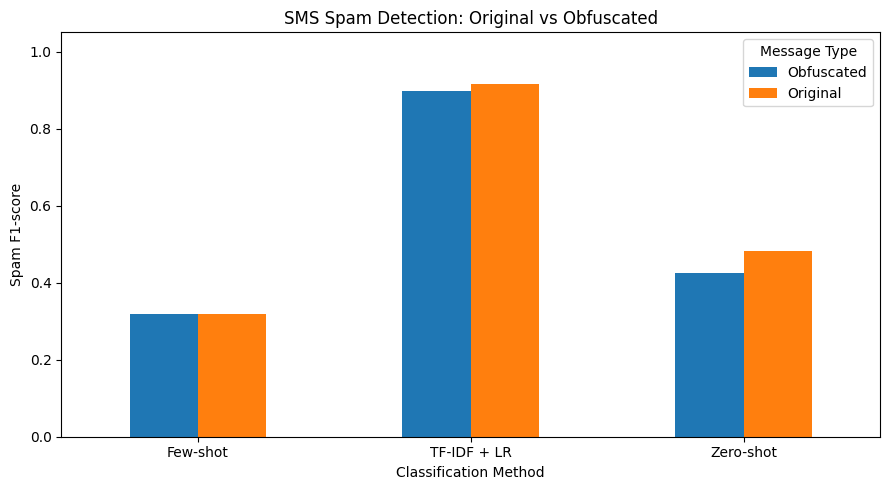


Confusion Matrix: TF-IDF + LR
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,208,2,0
spam,3,27,0
invalid,0,0,0



Confusion Matrix: Zero-shot
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,177,33,0
spam,10,20,0
invalid,0,0,0



Confusion Matrix: Few-shot
Rows = Actual | Columns = Predicted


,ham,spam,invalid
ham,82,128,0
spam,0,30,0
invalid,0,0,0


In [13]:
# Prepare comparison data
metric_plot = results.pivot(
    index="method",
    columns="scenario",
    values="spam_f1"
)

# Bar chart
ax = metric_plot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_ylim(0, 1.05)

ax.set_ylabel("Spam F1-score")

ax.set_xlabel("Classification Method")

ax.set_title(
    "SMS Spam Detection: Original vs Obfuscated"
)

ax.legend(title="Message Type")

plt.tight_layout()

# Save figure
plt.savefig(
    OUTPUT_DIR / "spam_f1_comparison.png",
    dpi=170
)

plt.show()


# Confusion matrices
for method in [
    "TF-IDF + LR",
    "Zero-shot",
    "Few-shot"
]:

    yp = predictions[(method, "Original")]

    labels = ["ham", "spam", "invalid"]

    matrix = confusion_matrix(
        y_true,
        yp,
        labels=labels
    )

    print(f"\nConfusion Matrix: {method}")
    print("Rows = Actual | Columns = Predicted")

    display(
        pd.DataFrame(
            matrix,
            index=labels,
            columns=labels
        )
    )

## 11. Error Analysis

We investigate situations where models make
incorrect predictions.

Specifically, we examine:

1. Spam messages correctly classified before
   obfuscation but missed afterward.

2. Messages where zero-shot and few-shot prompting
   produce different predictions.

This helps identify possible strengths and
weaknesses of each approach.

In [14]:
# Save message-level predictions
examples = eval_df[
    [
        "label",
        "text",
        "obfuscated_text",
        "was_changed"
    ]
].copy()


for (method, scenario), pred in predictions.items():

    column = (
        f"{method.replace(' ', '_').replace('-', '_')}_"
        f"{scenario}"
    )

    examples[column] = pred


examples.to_csv(
    OUTPUT_DIR / "message_predictions.csv",
    index=False
)


print("SPAM MISSED AFTER OBFUSCATION")


for method in [
    "TF-IDF + LR",
    "Zero-shot",
    "Few-shot"
]:

    original_pred = np.array(
        predictions[(method, "Original")]
    )

    modified_pred = np.array(
        predictions[(method, "Obfuscated")]
    )

    relevant = (
        (eval_df["label"] == "spam")
        & eval_df["was_changed"]
        & (original_pred == "spam")
        & (modified_pred != "spam")
    )

    print(
        method,
        "| Newly missed spam:",
        int(relevant.sum())
    )

    if relevant.any():

        display(
            eval_df.loc[
                relevant,
                ["text", "obfuscated_text"]
            ].head(3)
        )


# Compare zero-shot vs few-shot
print("\nZERO-SHOT VS FEW-SHOT DISAGREEMENTS")

p0 = np.array(
    predictions[("Zero-shot", "Original")]
)

p1 = np.array(
    predictions[("Few-shot", "Original")]
)

disagree = p0 != p1

comparison = eval_df.loc[
    disagree,
    ["label", "text"]
].copy()

comparison["zero_shot"] = p0[disagree]
comparison["few_shot"] = p1[disagree]

display(comparison.head(8))

SPAM MISSED AFTER OBFUSCATION
TF-IDF + LR | Newly missed spam: 1


,text,obfuscated_text
20,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...


Zero-shot | Newly missed spam: 4


,text,obfuscated_text
21,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...
128,Free Msg: Ringtone!From: http://tms. widelive....,fr33 Msg: Ringtone!From: http://tms. widelive....
157,Congratulations U can claim 2 VIP row A Ticket...,Congratulations U can cl@im 2 VIP row A Ticket...


Few-shot | Newly missed spam: 0

ZERO-SHOT VS FEW-SHOT DISAGREEMENTS


,label,text,zero_shot,few_shot
1,ham,How do you guys go to see movies on your side.,ham,spam
3,ham,I want to tell you how bad I feel that basical...,ham,spam
4,spam,"cmon babe, make me horny, *turn* me on! Txt me...",ham,spam
5,ham,Dont flatter yourself... Tell that man of mine...,ham,spam
7,ham,Yunny i'm walking in citylink now Ã¼ faster co...,ham,spam
9,ham,Congrats. That's great. I wanted to tell you n...,ham,spam
13,ham,This is wishing you a great day. Moji told me ...,ham,spam
17,ham,Goodo! Yes we must speak friday - egg-potato r...,ham,spam


## 12. Live SMS Classification Demo

This demonstration allows us to enter a new
SMS message and classify it using all three methods.

The output shows:

- Traditional ML prediction
- Zero-shot LLM prediction
- Few-shot LLM prediction

This demonstration can be used during the
classroom presentation.

In [15]:
# Change this message to test something new
DEMO_MESSAGE = (
    "Congratulations! You have won a free "
    "cash prize. Claim it now!"
)

print("SMS MESSAGE:")
print(DEMO_MESSAGE)

print("\nCLASSIFICATION RESULTS")

# Traditional baseline
baseline_result = baseline.predict(
    [DEMO_MESSAGE]
)[0]

print("TF-IDF + Logistic Regression:", baseline_result)

# LLM predictions
for strategy in ["Zero-shot", "Few-shot"]:

    prediction, raw_output, _ = flan_predict(
        [DEMO_MESSAGE],
        strategy
    )

    print(
        f"{strategy}: {prediction[0]}"
    )

    print(
        f"Raw model output: {raw_output[0]!r}"
    )

SMS MESSAGE:
Congratulations! You have won a free cash prize. Claim it now!

CLASSIFICATION RESULTS
TF-IDF + Logistic Regression: spam
Zero-shot: 1/1
Zero-shot: spam
Raw model output: 'Spam'
Few-shot: 1/1
Few-shot: spam
Raw model output: 'spam'


## 13. Export Experimental Results

The following results will be saved:

- Classification metrics
- Results on modified messages
- Individual message predictions
- F1-score comparison chart
- Experiment summary

These files can be included in the GitHub
repository and used for the final project report.

Results should be downloaded or saved to
Google Drive before ending the Colab session.

In [16]:
from shutil import make_archive

# Generate experiment summary
summary_lines = [

    "AI Course Project - SMS Spam Detection",

    f"Model: {MODEL_NAME}",

    f"Seed: {SEED}",

    f"Training samples: {len(train_df)}",

    f"Full held-out samples: {len(test_df)}",

    f"Evaluated samples: {len(eval_df)}",

    (
        "Messages modified by obfuscation: "
        f"{int(eval_df.was_changed.sum())}"
    ),

    "",

    "Results (full evaluated sample):",

    results.round(3).to_string(index=False),

    "",

    "Changed-only results:",

    changed_results.round(3).to_string(index=False)

]

# Save summary
(OUTPUT_DIR / "result_summary.txt").write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

# Create ZIP archive
zip_path = make_archive(
    "project_results",
    "zip",
    root_dir=".",
    base_dir=str(OUTPUT_DIR)
)

print("Created:", zip_path)

print("\nOutput files:")

for file in OUTPUT_DIR.iterdir():
    print("-", file.name)


# Download in Colab
try:
    from google.colab import files

    files.download(zip_path)

except ImportError:
    print("Run in Colab to download automatically.")

Created: /content/project_results.zip

Output files:
- result_summary.txt
- metrics_changed_only.csv
- spam_f1_comparison.png
- metrics.csv
- message_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusion and Future Work

This project compares a traditional machine learning
classifier against two prompting strategies using
a pretrained language model.

The evaluation focuses on:

- Classification accuracy
- Spam precision and recall
- F1-score
- Computational runtime
- Robustness to keyword obfuscation

### Discussion Questions

1. Which method achieved the highest spam F1-score?
2. Did few-shot prompting improve results?
3. Which approach was most affected by obfuscation?
4. What types of messages caused classification errors?
5. How did inference times compare?

### Limitations

- Evaluation uses a historical SMS dataset.
- The LLM is not fine-tuned.
- Only one LLM checkpoint is evaluated.
- Few-shot performance may depend on example selection.
- Only a limited number of obfuscation patterns are tested.
- The public dataset may have been encountered during
  the pretrained model's development.

### Future Work

Potential extensions include:

- Evaluating additional LLMs
- Testing different numbers of few-shot examples
- Fine-tuning a language model
- Evaluating multilingual spam messages
- Testing additional adversarial text modifications

### References

1. Almeida, T. A., Hidalgo, J. M. G., & Yamakami, A.
   Contributions to the Study of SMS Spam Filtering:
   New Collection and Results. ACM DocEng, 2011.

2. UCI Machine Learning Repository.
   SMS Spam Collection.
   https://archive.ics.uci.edu/dataset/228/sms+spam+collection

3. Chung, H. W., et al.
   Scaling Instruction-Finetuned Language Models, 2022.
   https://arxiv.org/abs/2210.11416

4. Google FLAN-T5-base.
   https://huggingface.co/google/flan-t5-base

5. Pedregosa, F., et al.
   Scikit-learn: Machine Learning in Python.
   JMLR, 2011.

In [ ]:
import torch
import time
import pandas as pd

@torch.inference_mode()
def score_candidate_labels(messages, batch_size=12):

    messages = list(messages)
    candidates = ["ham", "spam"]

    target_ids = tokenizer(
        candidates,
        padding=True,
        return_tensors="pt"
    )["input_ids"].to(DEVICE)

    all_predictions = []
    started = time.perf_counter()

    for start in range(0, len(messages), batch_size):

        batch = messages[start:start + batch_size]

        prompts = [
            build_prompt(str(msg), "Zero-shot")
            for msg in batch
        ]

        inputs = tokenizer(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
            return_tensors="pt"
        ).to(DEVICE)

        # Each message is paired with both candidate labels
        input_ids = inputs["input_ids"].repeat_interleave(2, dim=0)
        attention_mask = inputs["attention_mask"].repeat_interleave(2, dim=0)

        labels = target_ids.repeat(len(batch), 1)
        labels[labels == tokenizer.pad_token_id] = -100

        # Teacher-forced candidate scoring
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        log_probs = torch.log_softmax(
            outputs.logits.float(),
            dim=-1
        )

        valid = labels != -100

        token_scores = log_probs.gather(
            -1,
            labels.clamp(min=0).unsqueeze(-1)
        ).squeeze(-1)

        token_scores = token_scores.masked_fill(
            ~valid, 0
        )

        scores = token_scores.sum(dim=1).reshape(
            len(batch), 2
        )

        best_indices = scores.argmax(dim=1).tolist()

        all_predictions.extend(
            candidates[i] for i in best_indices
        )

    elapsed = time.perf_counter() - started

    return all_predictions, elapsed


# Evaluate original and obfuscated messages
e03_predictions = {}

for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:
    pred, elapsed = score_candidate_labels(
        eval_df[column]
    )

    e03_predictions[scenario] = pred

    print(f"\nE03 - {scenario}")
    print(f"Inference time: {elapsed:.2f} seconds")

    print(classification_report(
        eval_df["label"],
        pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    print("Predicted class distribution:")
    print(pd.Series(pred).value_counts())


E03 - Original
Inference time: 223.10 seconds
              precision    recall  f1-score   support

         ham       0.95      0.99      0.97       210
        spam       0.86      0.63      0.73        30

    accuracy                           0.94       240
   macro avg       0.91      0.81      0.85       240
weighted avg       0.94      0.94      0.94       240

Predicted class distribution:
ham     218
spam     22
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

char_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=60000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=SEED
    ))
])

# Same training data as E01/E02
char_model.fit(
    train_df["text"],
    train_df["label"]
)

# Same evaluation data
for scenario, column in [
    ("Original", "text"),
    ("Obfuscated", "obfuscated_text")
]:
    predictions_char = char_model.predict(
        eval_df[column]
    )

    print(f"\nCharacter TF-IDF - {scenario}")

    print(classification_report(
        eval_df["label"],
        predictions_char,
        labels=["ham", "spam"],
        zero_division=0
    ))

    print("Spam F1:", round(
        f1_score(
            eval_df["label"],
            predictions_char,
            pos_label="spam"
        ), 4
    ))

In [ ]:
modern_sms = pd.DataFrame([
    ("personal", "Hey, can you pick up groceries tonight?"),
    ("personal", "Your appointment is confirmed for Thursday."),

    ("political", "Hello, this is the campaign volunteer team. Our town hall is next week."),
    ("political", "Campaign update: Would you like to volunteer this weekend?"),
    ("political", "Urgent campaign fundraising deadline tonight. Please consider donating."),
    ("political", "Thank you for signing up for campaign event reminders."),

    ("phishing", "Unpaid toll detected. Enter your payment details immediately."),
    ("phishing", "Your bank account is locked. Verify your identity using this link."),
    ("phishing", "We cannot process your donation. Reply with your credit card number."),

    ("commercial", "Limited time! Get 50 percent off your next purchase."),
    ("commercial", "Exclusive offer for new customers. Sign up today."),
    ("commercial", "Congratulations! Claim your free gift card now.")
], columns=["topic", "text"])

# Run existing models
modern_sms["traditional_ml"] = baseline.predict(
    modern_sms["text"]
)

modern_sms["zero_shot"], _, _ = flan_predict(
    modern_sms["text"],
    "Zero-shot"
)

modern_sms["few_shot"], _, _ = flan_predict(
    modern_sms["text"],
    "Few-shot"
)

modern_sms["candidate_scoring"], _ = score_candidate_labels(
    modern_sms["text"]
)

display(modern_sms)

modern_sms.to_csv(
    OUTPUT_DIR / "modern_sms_case_study.csv",
    index=False
)

In [ ]:
from shutil import make_archive
from google.colab import files

zip_path = make_archive(
    "project_results_updated",
    "zip",
    root_dir=".",
    base_dir=str(OUTPUT_DIR)
)

files.download(zip_path)